# Exercice 7 : visualisation des logs météo stockés dans HDFS

On relit les fichiers `/hdfs-data/{country}/{city}/alerts.json` écrits par l'exercice 6
(une ligne JSON par message), puis on trace :
1. l'évolution de la température ;
2. l'évolution de la vitesse du vent ;
3. le nombre d'alertes vent et chaleur par niveau ;
4. le code météo le plus fréquent par pays.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, count, to_timestamp

spark = (
    SparkSession.builder.appName("ex7_visualisation")
    # mode local : les jobs des exercices 4 et 5 occupent déjà les 2 coeurs du worker,
    # et ici on fait juste une lecture batch de quelques centaines de lignes
    .master("local[*]")
    .getOrCreate()
)

## Lecture des logs HDFS

In [2]:
# * = tous les pays, * = toutes les villes
logs = spark.read.json("hdfs://namenode:9000/hdfs-data/*/*/alerts.json")
logs = logs.withColumn("event_time", to_timestamp("event_time"))

logs.printSchema()
print("Nombre de messages :", logs.count())
logs.orderBy("event_time").show(10, truncate=False)

root
 |-- city: string (nullable = true)
 |-- country: string (nullable = true)
 |-- event_time: timestamp (nullable = true)
 |-- heat_alert_level: string (nullable = true)
 |-- temperature: double (nullable = true)
 |-- weather_code: long (nullable = true)
 |-- wind_alert_level: string (nullable = true)
 |-- windspeed: double (nullable = true)

Nombre de messages : 249
+----------+--------------------+-----------------------+----------------+-----------+------------+----------------+---------+
|city      |country             |event_time             |heat_alert_level|temperature|weather_code|wind_alert_level|windspeed|
+----------+--------------------+-----------------------+----------------+-----------+------------+----------------+---------+
|Paris     |France              |2026-11-10 12:47:31.967|level_0         |11.9       |61          |level_0         |2.15     |
|Seville   |Spain               |2026-11-10 12:47:32.072|level_0         |21.4       |80          |level_0         |5.8

In [3]:
# Peu de données (quelques messages par minute) : on peut passer en pandas pour les graphiques
pdf = logs.orderBy("event_time").toPandas()
pdf.groupby(["country", "city"]).size()

country               city      
France                Paris         49
Iceland               Reykjavik     50
New Zealand           Wellington    50
Spain                 Seville       50
United Arab Emirates  Dubai         50
dtype: int64

## 1. Évolution de la température

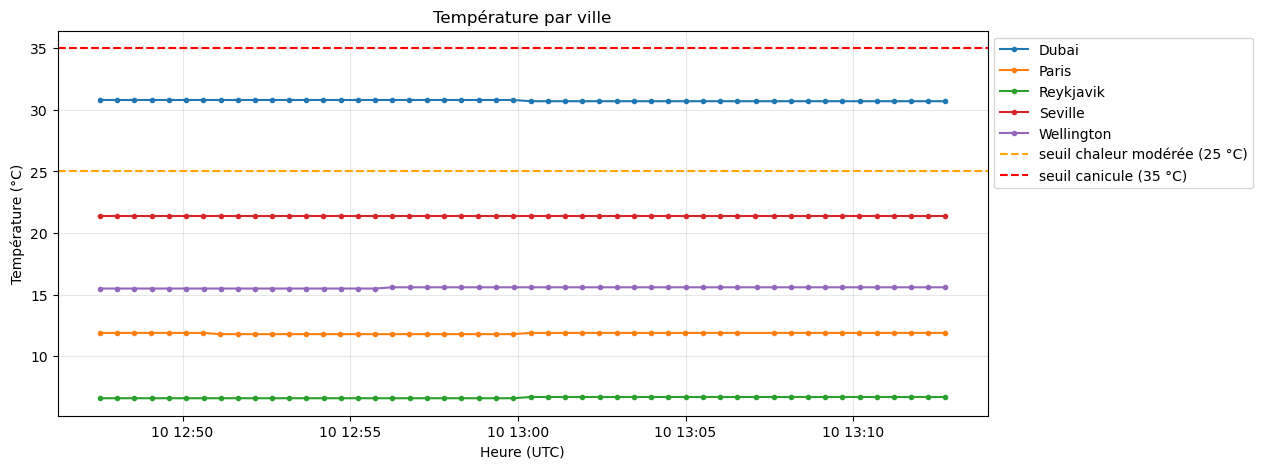

In [4]:
plt.figure(figsize=(12, 5))
for ville, groupe in pdf.groupby("city"):
    plt.plot(groupe["event_time"], groupe["temperature"], marker=".", label=ville)
plt.axhline(25, color="orange", linestyle="--", label="seuil chaleur modérée (25 °C)")
plt.axhline(35, color="red", linestyle="--", label="seuil canicule (35 °C)")
plt.title("Température par ville")
plt.xlabel("Heure (UTC)")
plt.ylabel("Température (°C)")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))  # légende à droite du graphique
plt.grid(alpha=0.3)
plt.show()

## 2. Évolution de la vitesse du vent

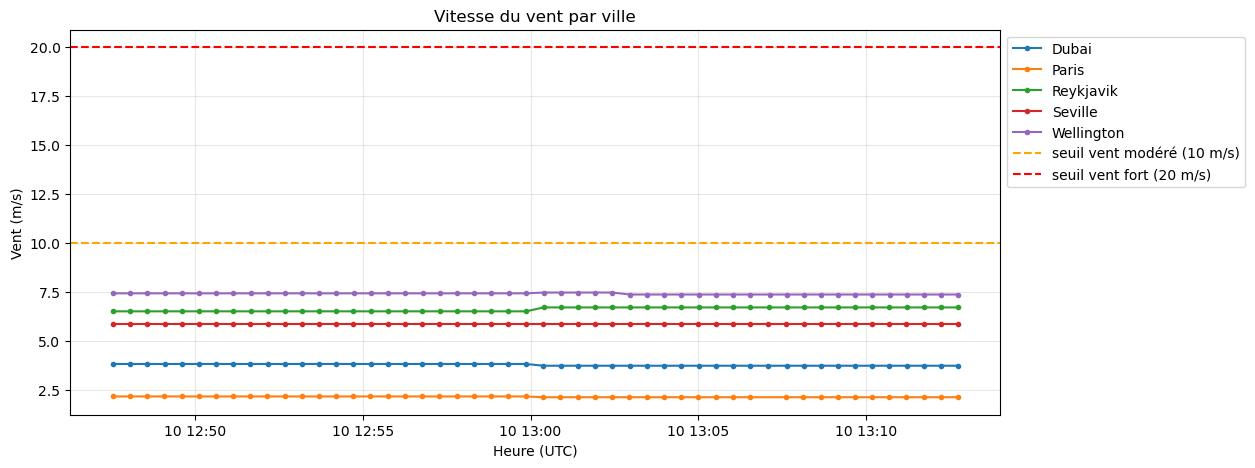

In [5]:
plt.figure(figsize=(12, 5))
for ville, groupe in pdf.groupby("city"):
    plt.plot(groupe["event_time"], groupe["windspeed"], marker=".", label=ville)
plt.axhline(10, color="orange", linestyle="--", label="seuil vent modéré (10 m/s)")
plt.axhline(20, color="red", linestyle="--", label="seuil vent fort (20 m/s)")
plt.title("Vitesse du vent par ville")
plt.xlabel("Heure (UTC)")
plt.ylabel("Vent (m/s)")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))  # légende à droite du graphique
plt.grid(alpha=0.3)
plt.show()

## 3. Nombre d'alertes vent et chaleur par niveau

         vent  chaleur
level_0   249      199
level_1     0       50
level_2     0        0


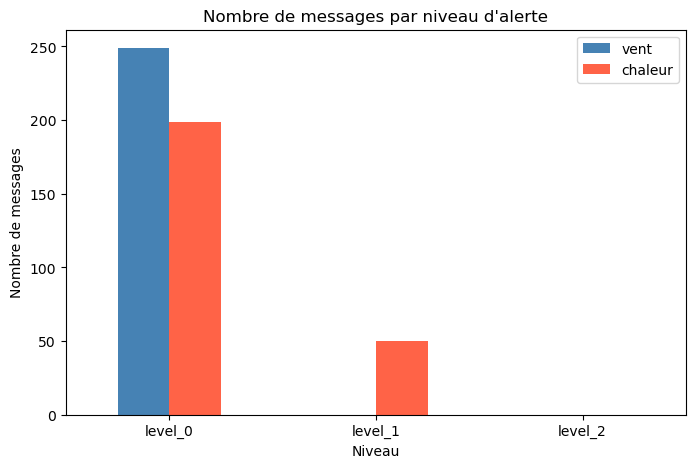

In [6]:
vent = logs.groupBy("wind_alert_level").agg(count("*").alias("nb")).toPandas()
chaleur = logs.groupBy("heat_alert_level").agg(count("*").alias("nb")).toPandas()

niveaux = ["level_0", "level_1", "level_2"]
alertes = pd.DataFrame({
    "vent": vent.set_index("wind_alert_level")["nb"].reindex(niveaux, fill_value=0),
    "chaleur": chaleur.set_index("heat_alert_level")["nb"].reindex(niveaux, fill_value=0),
})
print(alertes)

alertes.plot(kind="bar", figsize=(8, 5), color=["steelblue", "tomato"], rot=0)
plt.title("Nombre de messages par niveau d'alerte")
plt.xlabel("Niveau")
plt.ylabel("Nombre de messages")
plt.show()

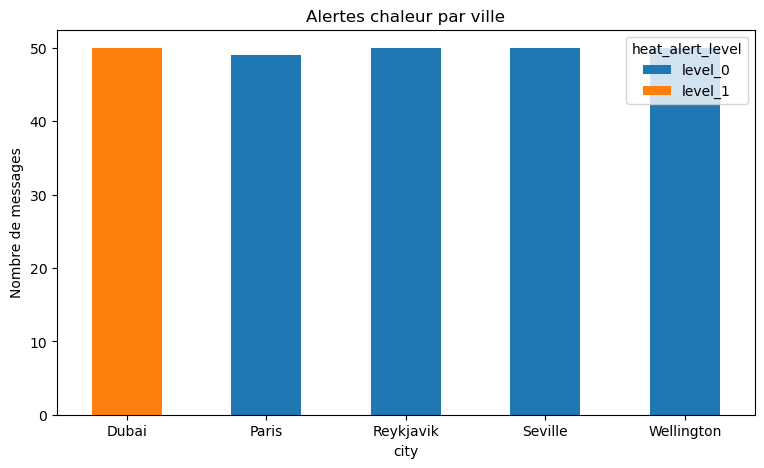

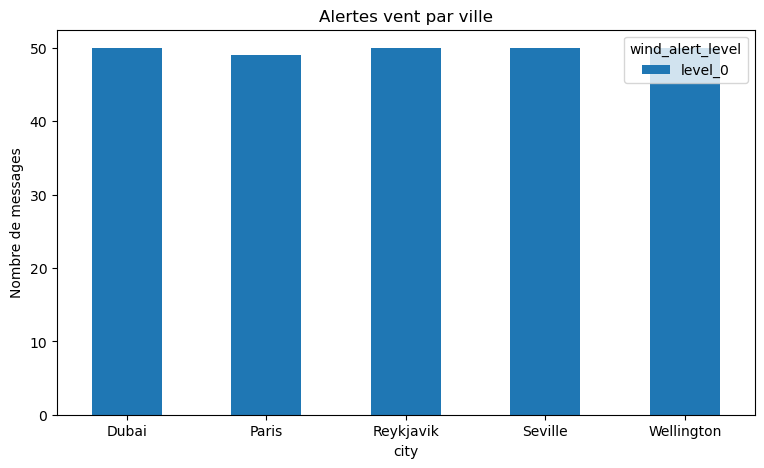

In [7]:
# Même chose, détaillé par ville
par_ville = pdf.groupby(["city", "heat_alert_level"]).size().unstack(fill_value=0)
par_ville.plot(kind="bar", stacked=True, figsize=(9, 5), rot=0)
plt.title("Alertes chaleur par ville")
plt.ylabel("Nombre de messages")
plt.show()

par_ville = pdf.groupby(["city", "wind_alert_level"]).size().unstack(fill_value=0)
par_ville.plot(kind="bar", stacked=True, figsize=(9, 5), rot=0)
plt.title("Alertes vent par ville")
plt.ylabel("Nombre de messages")
plt.show()

## 4. Code météo le plus fréquent par pays

In [8]:
# Signification des codes météo WMO renvoyés par Open-Meteo
CODES_WMO = {
    0: "Ciel dégagé", 1: "Plutôt dégagé", 2: "Partiellement nuageux", 3: "Couvert",
    45: "Brouillard", 48: "Brouillard givrant",
    51: "Bruine légère", 53: "Bruine modérée", 55: "Bruine dense",
    61: "Pluie faible", 63: "Pluie modérée", 65: "Pluie forte",
    71: "Neige faible", 73: "Neige modérée", 75: "Neige forte",
    80: "Averses faibles", 81: "Averses modérées", 82: "Averses violentes",
    95: "Orage", 96: "Orage avec grêle", 99: "Orage avec forte grêle",
}

codes = logs.groupBy("country", "weather_code").agg(count("*").alias("nb")).toPandas()

# pour chaque pays, on garde la ligne avec le plus grand nombre
plus_frequent = codes.sort_values("nb", ascending=False).drop_duplicates("country").sort_values("country")
plus_frequent["libelle"] = plus_frequent["weather_code"].map(CODES_WMO)
plus_frequent

,country,weather_code,nb,libelle
4,France,61,49,Pluie faible
3,Iceland,3,50,Couvert
0,New Zealand,53,50,Bruine modérée
2,Spain,80,50,Averses faibles
1,United Arab Emirates,0,50,Ciel dégagé


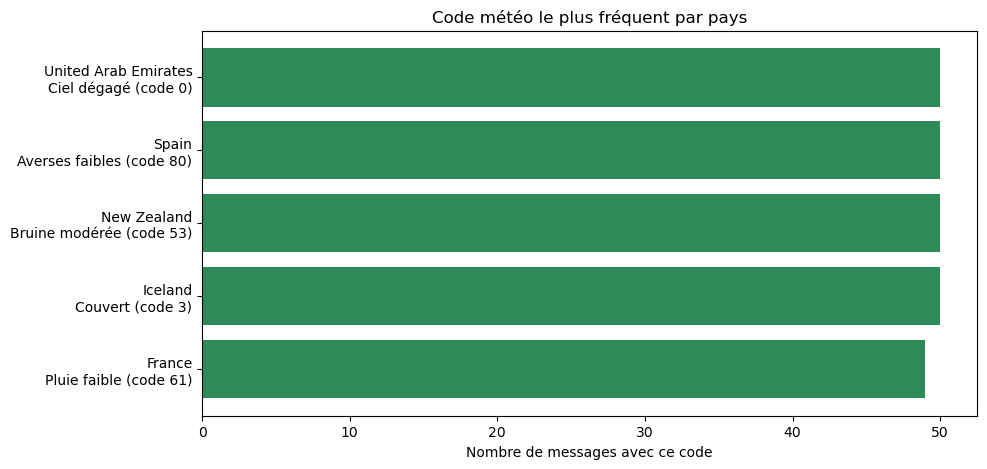

In [9]:
etiquettes = plus_frequent["country"] + "\n" + plus_frequent["libelle"] + " (code " + plus_frequent["weather_code"].astype(str) + ")"
plt.figure(figsize=(10, 5))
plt.barh(etiquettes, plus_frequent["nb"], color="seagreen")
plt.title("Code météo le plus fréquent par pays")
plt.xlabel("Nombre de messages avec ce code")
plt.show()

In [10]:
spark.stop()